# 05 · Chapter 3: healthy controls and external validation
UCSC Toil processes TCGA and GTEx with one pipeline, so tumors can be compared with tissue from people without cancer.

In [1]:
import os, glob
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.precision', 3); pd.set_option('display.max_rows', 80)
R = 'results/external'
TAB, FIG = f'{R}/tables', f'{R}/figures'
summary = pd.read_csv(f'{TAB}/summary.csv')
best = lambda k: (summary[(summary.model == 'logreg') & (summary.k == k) & ~summary.selector.isin(['random', 'variance', 'all_genes'])]
                  .groupby(['cancer', 'task']).auc_mean.max().rename(f'best_{k}'))

## Minimal panel per task
Smallest panel that is non-inferior to all genes (corrected repeated-CV test), and the smallest reaching 90% sensitivity at 95% specificity.

In [2]:
pd.read_csv(f'{TAB}/minimal_panel.csv')

,cancer,task,model,n_genes_all,auc_all_genes,auc_best_1,auc_best_10,smallest_retained_k,auc_random_10,smallest_k_sens90,sens_all_genes
0,BRCA_GTEx,normal_vs_healthy,logreg,13550,1.0,0.996,1.0,2.0,0.989,1,1.0
1,BRCA_GTEx,tumor_vs_healthy,logreg,13482,1.0,1.000,1.0,1.0,0.993,1,1.0
2,LUAD_GTEx,normal_vs_healthy,logreg,13714,1.0,0.993,1.0,2.0,0.989,1,1.0
3,LUAD_GTEx,tumor_vs_healthy,logreg,13802,1.0,0.995,1.0,2.0,0.990,1,1.0


## AUC as the panel shrinks (logistic regression)

In [3]:
allg = summary[(summary.model == 'logreg') & (summary.selector == 'all_genes')].set_index(['cancer', 'task']).auc_mean.rename('all_genes')
rnd = summary[(summary.model == 'logreg') & (summary.selector == 'random') & (summary.k == 10)].set_index(['cancer', 'task']).auc_mean.rename('random_10')
pd.concat([allg, best(500), best(50), best(10), best(5), best(1), rnd], axis=1)

all_genes  best_500  best_50  best_10  best_5  \
cancer    task                                                               
BRCA_GTEx normal_vs_healthy        1.0       1.0      1.0      1.0   1.000   
          tumor_vs_healthy         1.0       1.0      1.0      1.0   1.000   
LUAD_GTEx normal_vs_healthy        1.0       1.0      1.0      1.0   1.000   
          tumor_vs_healthy         1.0       1.0      1.0      1.0   0.999   

                             best_1  random_10  
cancer    task                                  
BRCA_GTEx normal_vs_healthy   0.996      0.989  
          tumor_vs_healthy    1.000      0.993  
LUAD_GTEx normal_vs_healthy   0.993      0.989  
          tumor_vs_healthy    0.995      0.990

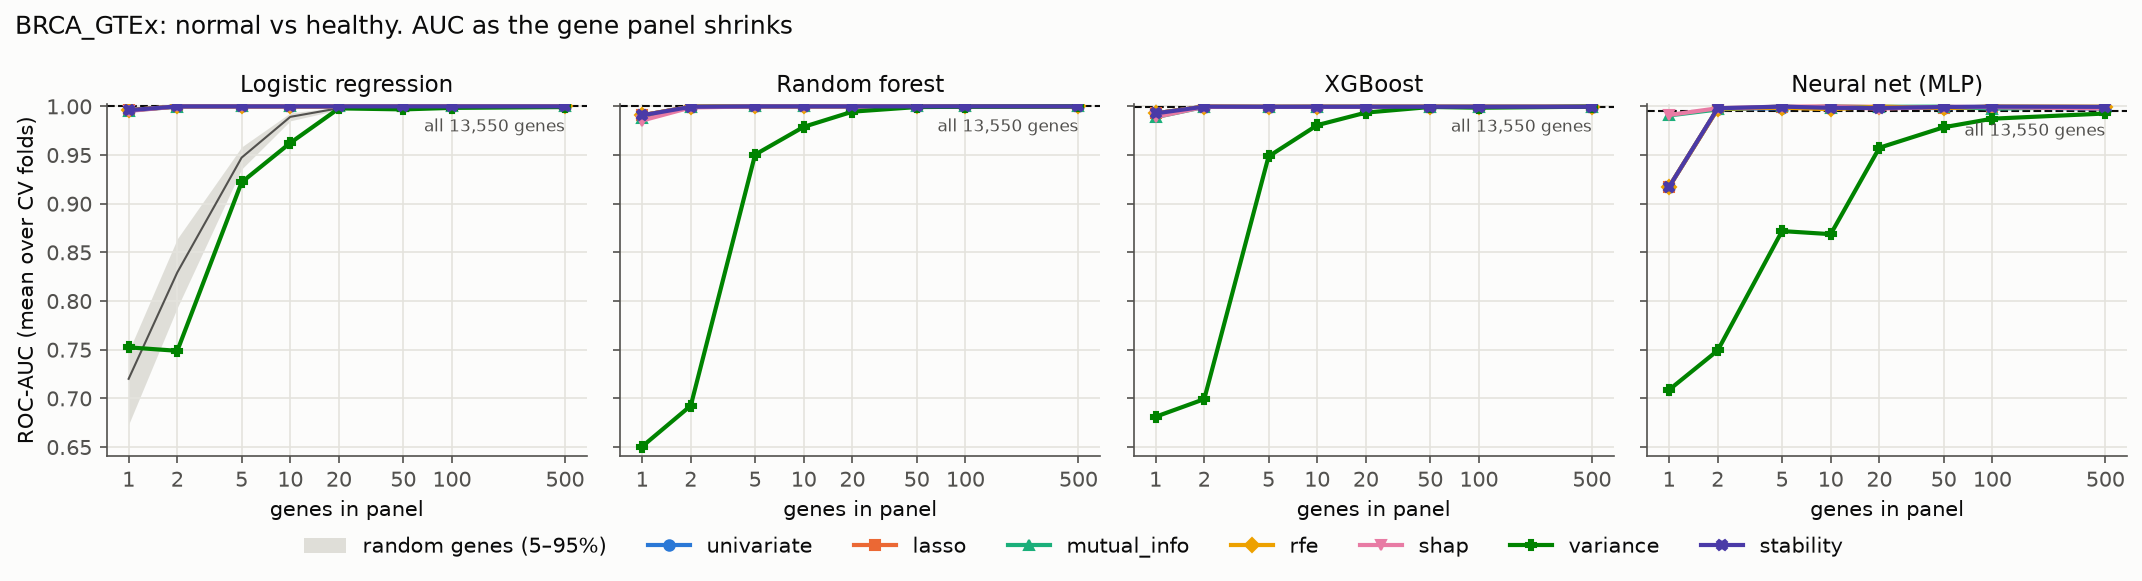

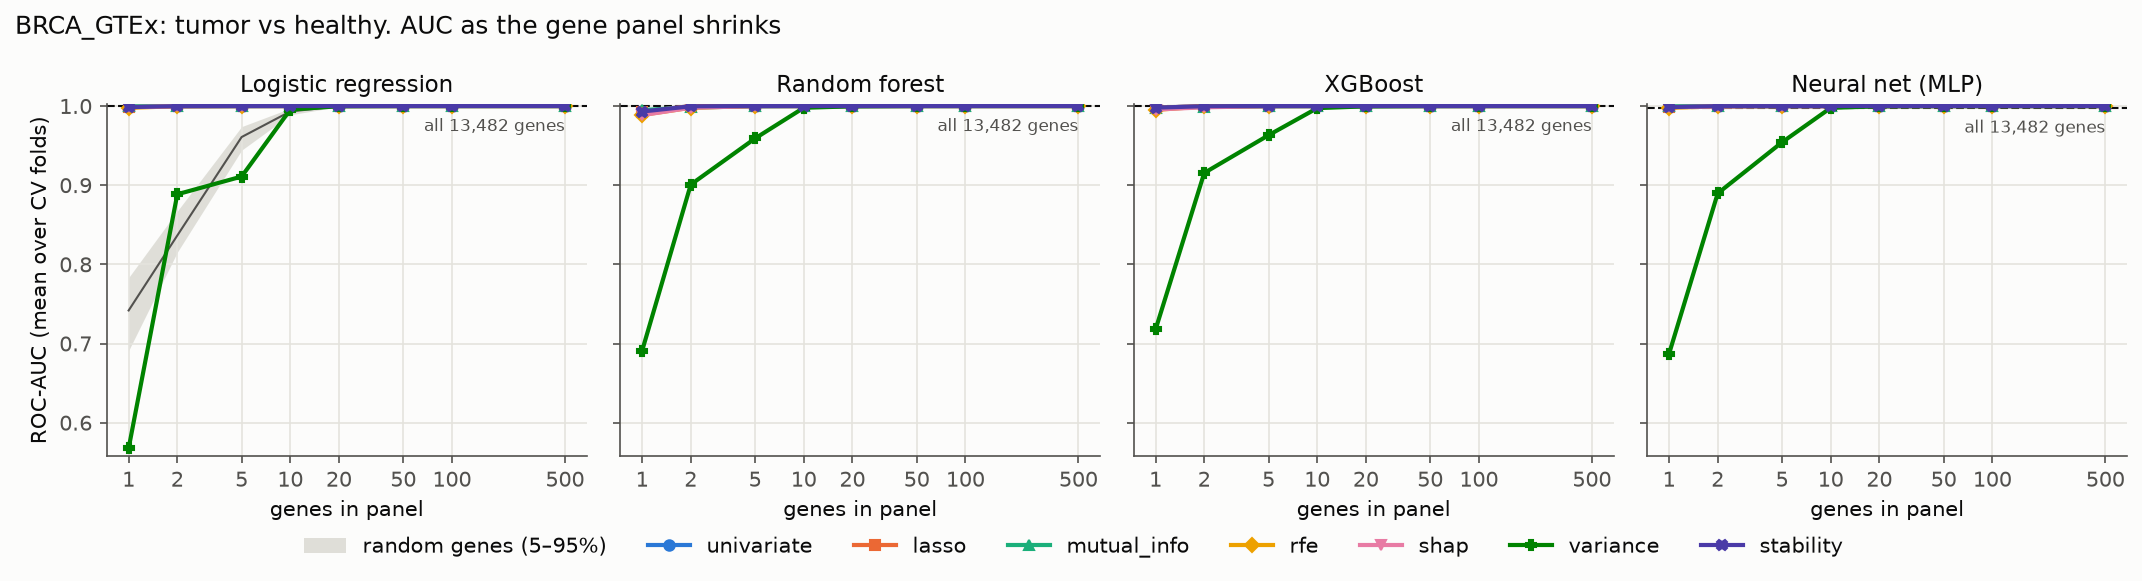

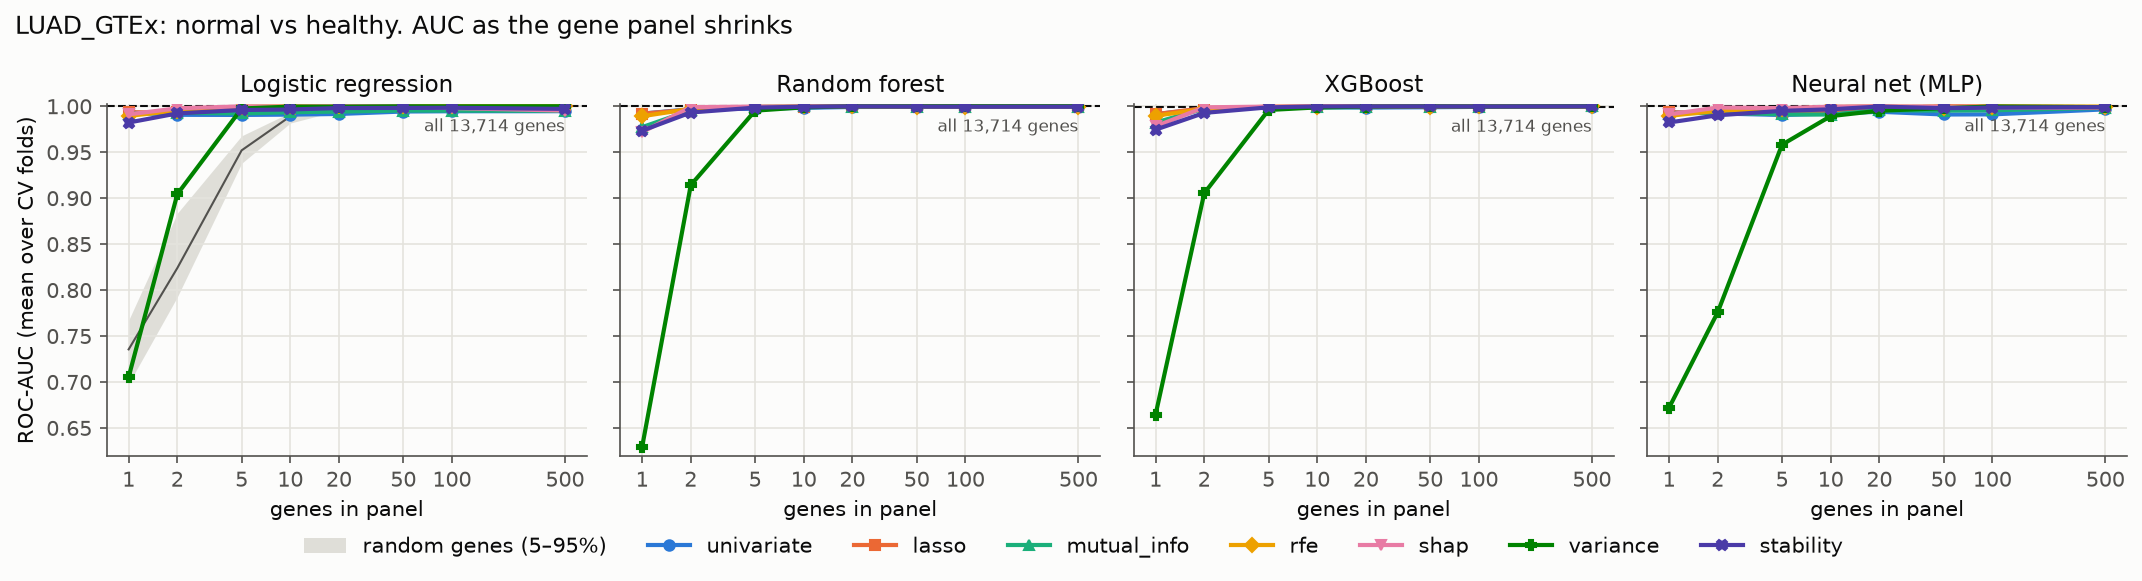

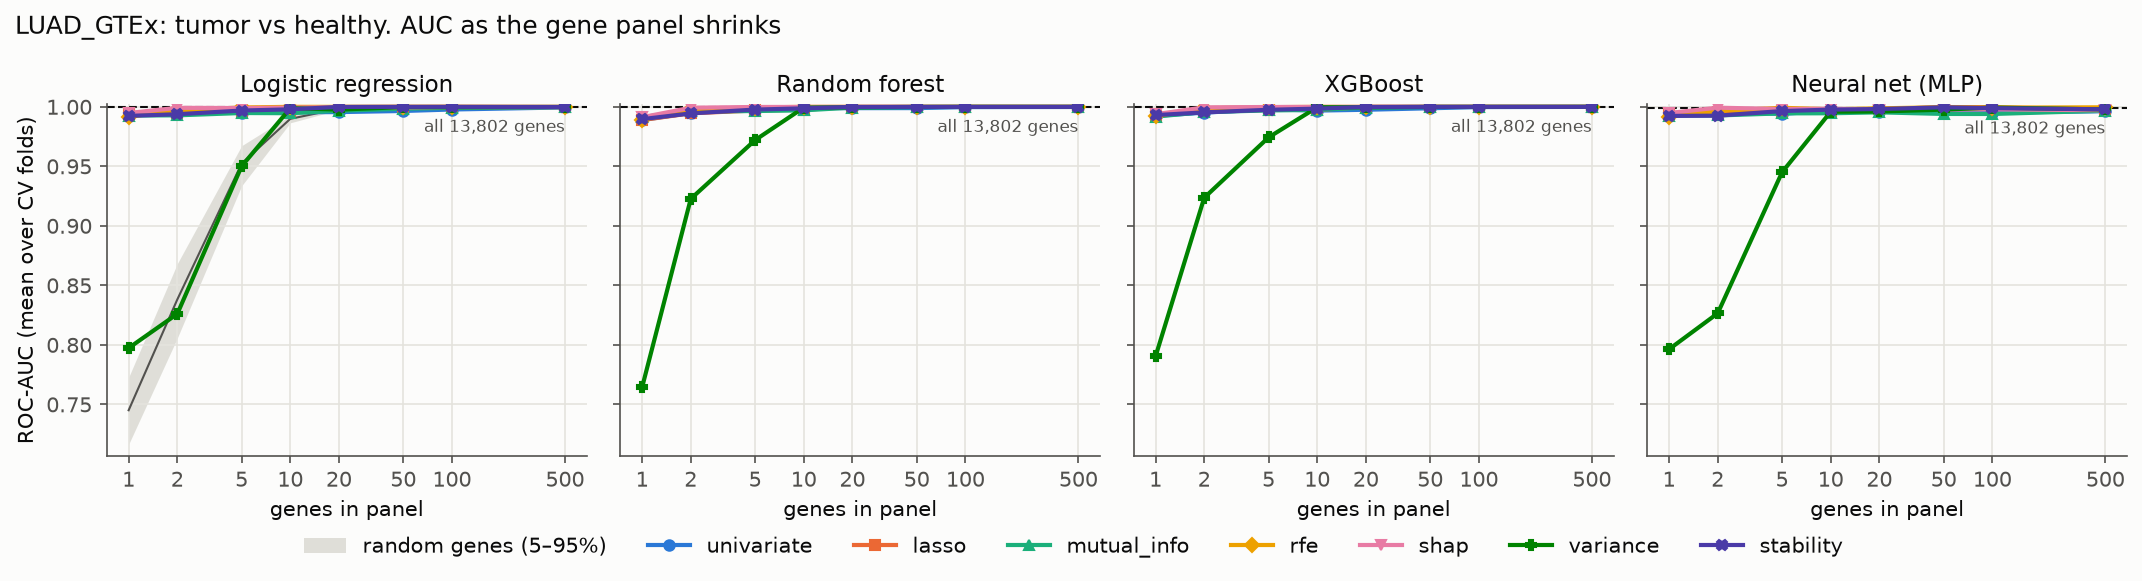

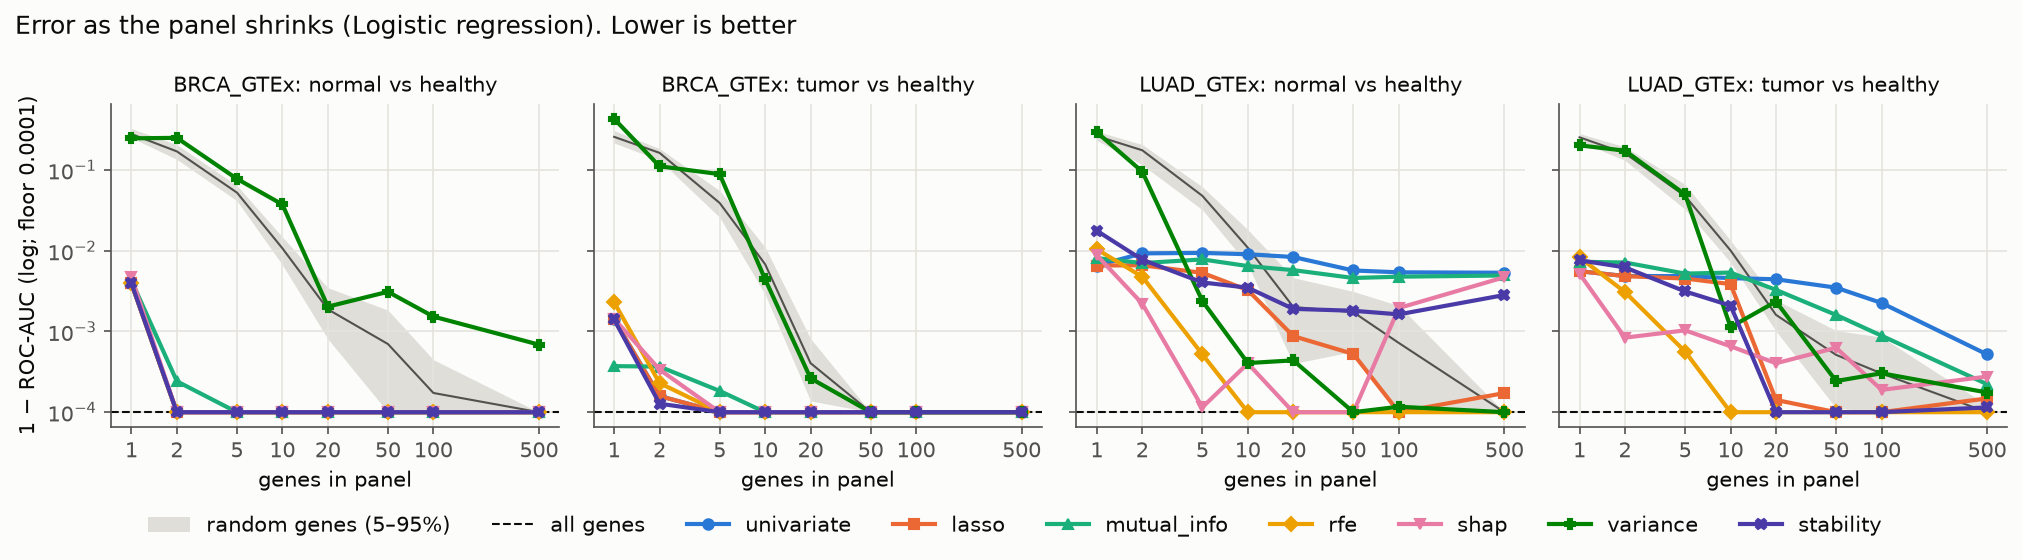

In [4]:
for f in sorted(glob.glob(f'{FIG}/auc_vs_k_*.png')) + [f'{FIG}/error_vs_k_logreg.png']:
    display(Image(f))

## Frozen chapter-1 models on a new pipeline and truly healthy tissue

In [5]:
ext = pd.read_csv(f'{TAB}/external.csv')
ext.pivot_table(index=['tissue', 'selector', 'k'], columns='setting', values=['auc', 'spec']).round(3)

auc                        \
setting                 external_harmonized external_raw internal   
tissue selector   k                                                 
breast all_genes  15828               0.999        0.999    0.999   
       lasso      1                   0.984        0.984    0.980   
                  2                   0.997        0.997    0.993   
                  5                   0.998        1.000    0.999   
                  10                  0.999        1.000    0.999   
                  20                  0.998        0.987    0.999   
                  50                  0.997        0.999    0.999   
                  100                 0.999        0.999    0.999   
                  500                 0.999        0.998    1.000   
       rfe        1                   0.995        0.995    0.992   
                  2                   0.995        0.997    0.998   
                  5                   0.999        0.999    0.999   
                  10                  0.999        1.000    1.000   
                  20                  0.997        1.000    1.000   
                  50                  0.999        1.000    1.000   
                  100                 1.000        0.999    1.000   
                  500                 0.999        0.999    0.999   
       univariate 1                   0.977        0.977    0.981   
                  2                   0.996        0.998    0.992   
                  5                   1.000        0.999    0.996   
                  10                  1.000        1.000    0.999   
                  20                  1.000        1.000    0.999   
                  50                  1.000        1.000    1.000   
                  100                 1.000        1.000    0.999   
                  500                 0.998        0.998    0.999   
lung   all_genes  16013               0.984        0.984    1.000   
       lasso      1                   0.911        0.911    0.985   
                  2                   0.970        0.966    0.999   
                  5                   0.976        0.975    0.998   
                  10                  0.984        0.985    0.999   
                  20                  0.993        0.993    1.000   
                  50                  0.996        0.996    1.000   
                  100                 0.999        0.998    1.000   
                  500                 0.998        0.997    1.000   
       rfe        1                   0.932        0.932    0.997   
                  2                   0.963        0.966    0.998   
                  5                   0.973        0.975    0.999   
                  10                  0.985        0.984    0.999   
                  20                  0.993        0.989    1.000   
                  50                  0.997        0.994    1.000   
                  100                 0.998        0.997    1.000   
                  500                 0.997        0.995    1.000   
       univariate 1                   0.922        0.922    0.985   
                  2                   0.970        0.966    0.999   
                  5                   0.971        0.972    0.998   
                  10                  0.980        0.978    0.999   
                  20                  0.987        0.989    0.999   
                  50                  0.976        0.983    0.999   
                  100                 0.983        0.990    1.000   
                  500                 0.993        0.993    1.000   

                                       spec                        
setting                 external_harmonized external_raw internal  
tissue selector   k                                                
breast all_genes  15828               0.987        0.200    1.000  
       lasso      1                   0.884        0.618    0.921  
                  2                   0.97